# Phase 2: Exploratory Data Analysis (EDA)
## AI4I 2020 Predictive Maintenance Dataset

**Project**: `AI-Predictive-Maintenance-IoT`  
**Dataset**: [UCI AI4I 2020 Predictive Maintenance Dataset](https://archive.ics.uci.edu/dataset/601/ai4i+2020+predictive+maintenance+dataset)  
**Author**: Antigravity (Senior Developer)  
**Status**: Exploratory Analysis (No Model Training)

---

### Notebook Objective
This notebook demonstrates a rigorous, reproducible exploratory data analysis of the AI4I 2020 Predictive Maintenance benchmark dataset. It utilizes our reusable project data loader (`src.data`), validates data contracts, examines physical operating parameters, evaluates class imbalance, studies failure modes, and saves key analytical figures for project documentation.

> **Important**: This dataset is a **synthetic benchmark** modeling real milling machine operations. It does not represent uncurated live production telemetry.


In [1]:
# 1. Environment & Path Setup
import sys
from pathlib import Path

# Resolve project root relative to notebook directory
project_root = Path.cwd().resolve()
if project_root.name == "notebooks":
    project_root = project_root.parent

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

print(f"Project root resolved to: {project_root}")


Project root resolved to: D:\Projects\Artificial Intelligence\AI-Powered Predictive Maintenance for IoT Devices


## 1. Dataset Ingestion & Schema Validation
We load the raw dataset through our reusable module `src.data.load_ai4i_dataset`. This guarantees:
- Strict schema validation
- Deterministic path resolution
- No silent dropping of records or modification of raw labels


In [2]:
from src.data import load_ai4i_dataset, TARGET_COLUMN, NUMERICAL_FEATURES, FAILURE_TYPE_COLUMNS

# Load dataset and obtain validation report
df, report = load_ai4i_dataset()

print(report.summary())


Validation Status: PASSED
Dimensions: 10000 rows x 14 columns
Duplicate Rows: 0
Total Missing Values: 0
Target Distribution ('Machine failure'): {0: 9661, 1: 339}
Target Percentages: {0: 96.61, 1: 3.39}


## 2. Dataset Dimensions, Schema, and Summary Statistics
Here we inspect the dataframe shape, feature types, and basic descriptive statistics (mean, standard deviation, quartiles, min/max).


In [3]:
# Display basic info and first 5 records
print(f"Shape: {df.shape[0]} rows x {df.shape[1]} columns\n")
print("Column Data Types:")
print(df.dtypes)

df.head()


Shape: 10000 rows x 14 columns

Column Data Types:
UDI                          int64
Product ID                     str
Type                           str
Air temperature [K]        float64
Process temperature [K]    float64
Rotational speed [rpm]       int64
Torque [Nm]                float64
Tool wear [min]              int64
Machine failure              int64
TWF                          int64
HDF                          int64
PWF                          int64
OSF                          int64
RNF                          int64
dtype: object


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [4]:
# Descriptive statistics for numerical operating parameters
df[NUMERICAL_FEATURES].describe().T


,count,mean,std,min,25%,50%,75%,max
Air temperature [K],10000.0,300.00493,2.000259,295.3,298.3,300.1,301.5,304.5
Process temperature [K],10000.0,310.00556,1.483734,305.7,308.8,310.1,311.1,313.8
Rotational speed [rpm],10000.0,1538.77610,179.284096,1168.0,1423.0,1503.0,1612.0,2886.0
Torque [Nm],10000.0,39.98691,9.968934,3.8,33.2,40.1,46.8,76.6
Tool wear [min],10000.0,107.95100,63.654147,0.0,53.0,108.0,162.0,253.0


## 3. Data Quality Audit: Missing Values and Duplicates
In real-world IoT datasets, sensor dropouts, transmission packet loss, and sensor drift are common. We audit the raw dataset for nulls and duplicated keys.


In [5]:
missing = df.isnull().sum()
duplicates = df.duplicated().sum()
udi_duplicates = df['UDI'].duplicated().sum()

print(f"Total duplicate rows: {duplicates}")
print(f"Unique UDI values: {df['UDI'].nunique()} (expected 10,000)")
print("\nMissing values per column:")
print(missing)


Total duplicate rows: 0
Unique UDI values: 10000 (expected 10,000)

Missing values per column:
UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64


## 4. Target Distribution & Class Imbalance
In industrial predictive maintenance, machinery failure is an anomalous, infrequent event. Machine learning algorithms must be configured to handle severe class imbalance to avoid predicting the majority class unconditionally.


Normal operations (0): 9661 (96.61%)
Failure events (1):    339 (3.39%)
Class Imbalance Ratio: 28.50 : 1


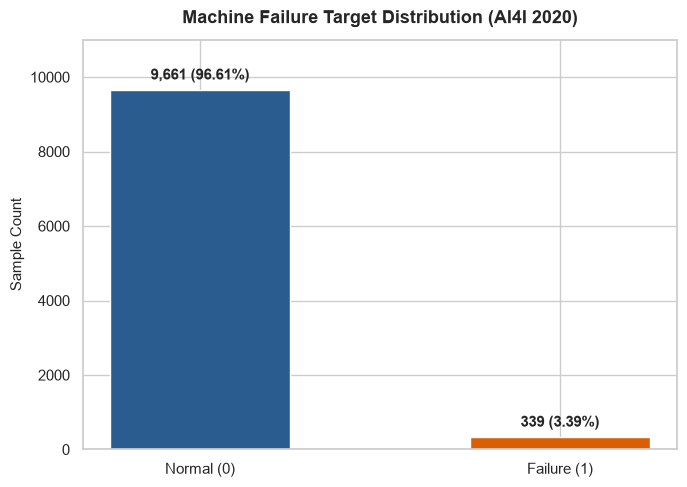

Saved figure to: D:\Projects\Artificial Intelligence\AI-Powered Predictive Maintenance for IoT Devices\images\target_distribution.png


In [6]:
import matplotlib.pyplot as plt
import seaborn as sns
import json

# Configure visual style
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.size'] = 11

counts = df[TARGET_COLUMN].value_counts()
pcts = df[TARGET_COLUMN].value_counts(normalize=True) * 100
imbalance_ratio = counts[0] / counts[1]

print(f"Normal operations (0): {counts[0]} ({pcts[0]:.2f}%)")
print(f"Failure events (1):    {counts[1]} ({pcts[1]:.2f}%)")
print(f"Class Imbalance Ratio: {imbalance_ratio:.2f} : 1")

# Visualizing target distribution
fig, ax = plt.subplots(figsize=(7, 5))
bars = ax.bar(["Normal (0)", "Failure (1)"], [counts[0], counts[1]], color=["#2b5c8f", "#d95f02"], width=0.5)

for bar in bars:
    height = bar.get_height()
    ax.annotate(f"{height:,} ({height/len(df)*100:.2f}%)",
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 5), textcoords="offset points",
                ha='center', va='bottom', fontweight='bold')

ax.set_title("Machine Failure Target Distribution (AI4I 2020)", fontsize=13, fontweight='bold', pad=12)
ax.set_ylabel("Sample Count", fontsize=11)
ax.set_ylim(0, 11000)

images_dir = project_root / "images"
images_dir.mkdir(parents=True, exist_ok=True)
fig_path = images_dir / "target_distribution.png"
plt.tight_layout()
plt.savefig(fig_path, dpi=300)
plt.show()
print(f"Saved figure to: {fig_path}")


## 5. Numeric Sensor & Operating Condition Distributions
We examine the probability density and distributions of the 5 numerical sensors, grouped by machine operational state (`Normal` vs `Failure`).
Notice the physical distribution shifts:
- **Rotational Speed**: Failures exhibit both very low speeds (stall/high friction) and high speed regimes.
- **Torque**: Higher torque is heavily correlated with failure events.
- **Tool Wear**: Failures are disproportionately concentrated in tools with high cumulative machining time (>150 minutes).


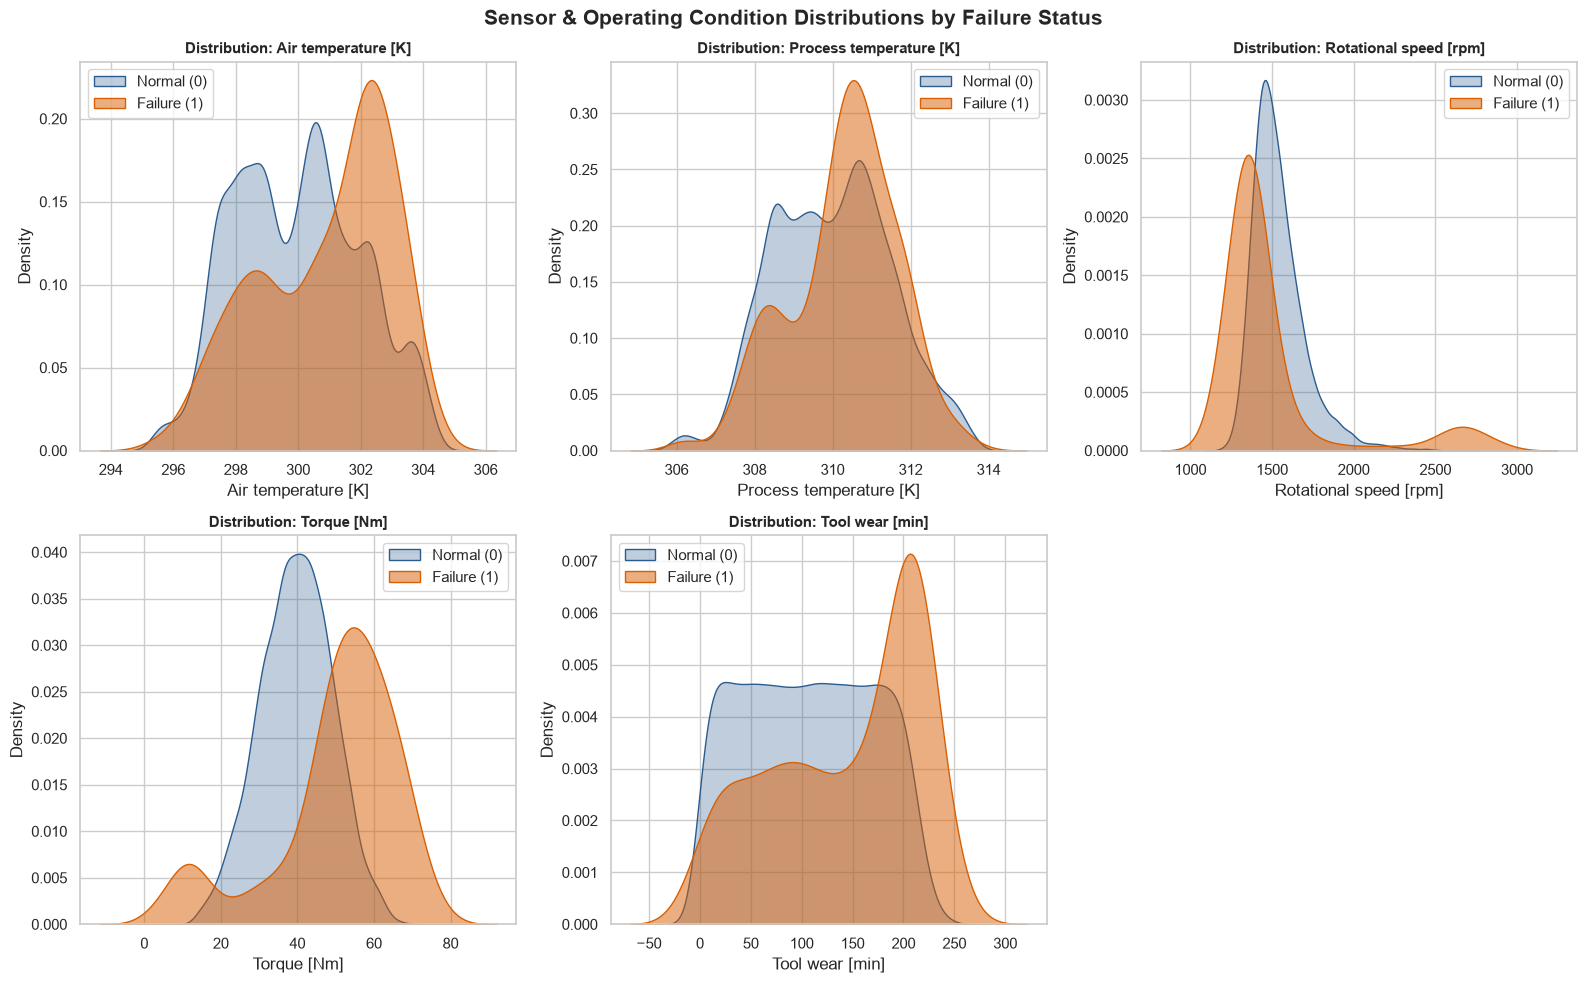

Saved figure to: D:\Projects\Artificial Intelligence\AI-Powered Predictive Maintenance for IoT Devices\images\sensor_distributions.png


In [7]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for idx, feature in enumerate(NUMERICAL_FEATURES):
    ax = axes[idx]
    sns.kdeplot(data=df[df[TARGET_COLUMN] == 0], x=feature, ax=ax, label="Normal (0)", fill=True, color="#2b5c8f", alpha=0.3)
    sns.kdeplot(data=df[df[TARGET_COLUMN] == 1], x=feature, ax=ax, label="Failure (1)", fill=True, color="#d95f02", alpha=0.5)
    ax.set_title(f"Distribution: {feature}", fontsize=11, fontweight='bold')
    ax.set_ylabel("Density")
    ax.legend()

# Remove unused 6th subplot
fig.delaxes(axes[5])

plt.suptitle("Sensor & Operating Condition Distributions by Failure Status", fontsize=15, fontweight='bold', y=0.98)
plt.tight_layout()
fig_dist_path = images_dir / "sensor_distributions.png"
plt.savefig(fig_dist_path, dpi=300)
plt.show()
print(f"Saved figure to: {fig_dist_path}")


## 6. Feature Correlations & Causation Discussion

> **Critical Data Science Note**:
> **Correlation does not establish causation.**
> A high Pearson or Spearman correlation indicates statistical co-variation in the simulated dataset, not a direct mechanical cause. For instance, `Torque` and `Rotational speed` are mechanically coupled via mechanical power ($P = \tau \cdot \omega$), meaning high torque naturally occurs at lower speeds under constant motor power.

Below is the correlation matrix across all numeric features, the primary target, and individual failure flags.


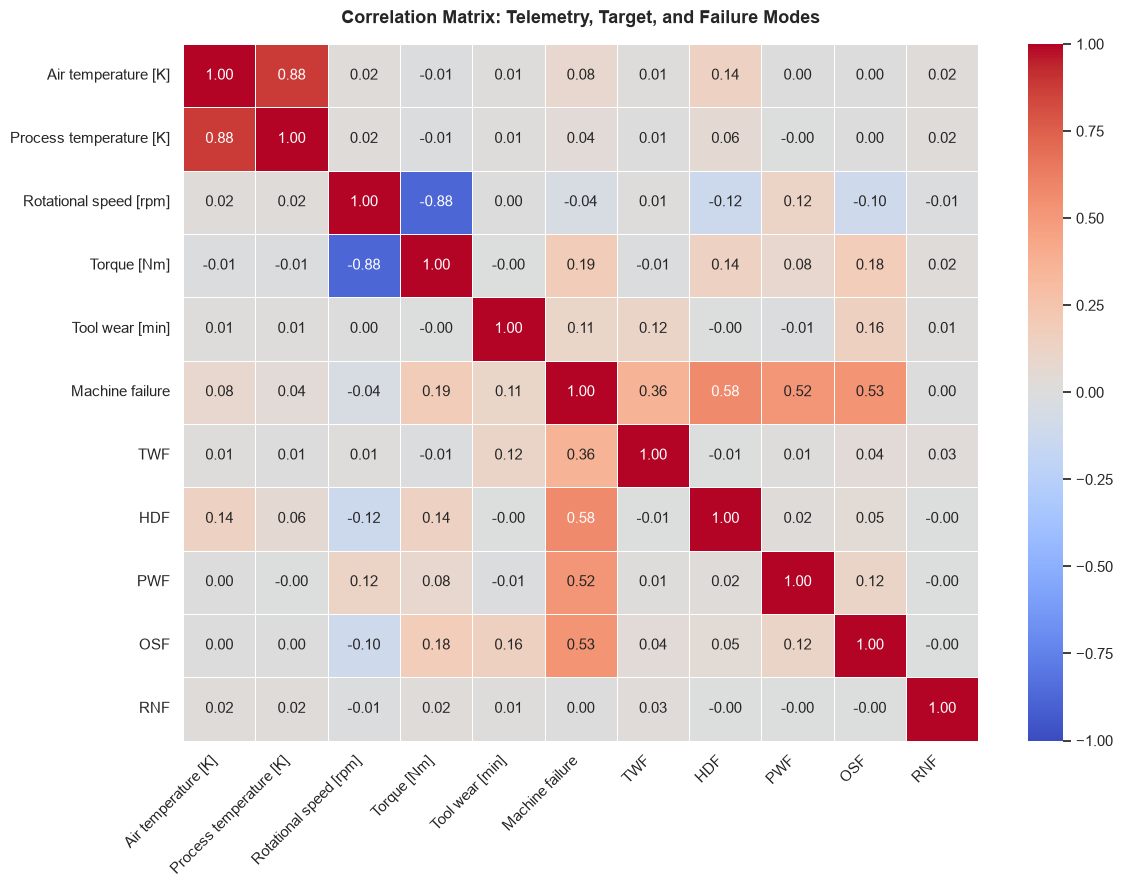

Saved figure to: D:\Projects\Artificial Intelligence\AI-Powered Predictive Maintenance for IoT Devices\images\correlation_matrix.png


In [8]:
analysis_cols = NUMERICAL_FEATURES + [TARGET_COLUMN] + FAILURE_TYPE_COLUMNS
corr_matrix = df[analysis_cols].corr()

fig, ax = plt.subplots(figsize=(12, 9))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", cbar=True, ax=ax,
            linewidths=0.5, vmin=-1.0, vmax=1.0)
ax.set_title("Correlation Matrix: Telemetry, Target, and Failure Modes", fontsize=13, fontweight='bold', pad=15)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()

fig_corr_path = images_dir / "correlation_matrix.png"
plt.savefig(fig_corr_path, dpi=300)
plt.show()
print(f"Saved figure to: {fig_corr_path}")


## 7. Failure Mode Attribution & In-Depth Consistency Analysis
The dataset includes five specific failure modes:
1. **HDF (Heat Dissipation Failure)**: Thermal dissipation failure ($\Delta T < 8.6\text{ K}$ and $\text{speed} < 1,380\text{ rpm}$).
2. **OSF (Overstrain Failure)**: Mechanical overload ($	ext{tool wear} \times 	ext{torque}$ exceeds threshold).
3. **PWF (Power Failure)**: Mechanical power outside $[3500\text{ W}, 9000\text{ W}]$.
4. **TWF (Tool Wear Failure)**: Cumulative wear exceeding limit (200-240 minutes).
5. **RNF (Random Failure)**: Uncorrelated random hardware failure.

### Data Nuances Discovered
We verify the logical consistency between the primary label `Machine failure` and the 5 specific failure flags.


Failure Mode Counts:
  - HDF: 115 (1.15% of all records, 33.9% of failures)
  - OSF: 98 (0.98% of all records, 28.9% of failures)
  - PWF: 95 (0.95% of all records, 28.0% of failures)
  - TWF: 46 (0.46% of all records, 13.6% of failures)
  - RNF: 19 (0.19% of all records, 5.6% of failures)

Anomalies & Nuances:
  - Failures without any specific mode flagged (Unattributed): 9
  - RNF == 1 where Machine failure was NOT asserted (0): 18


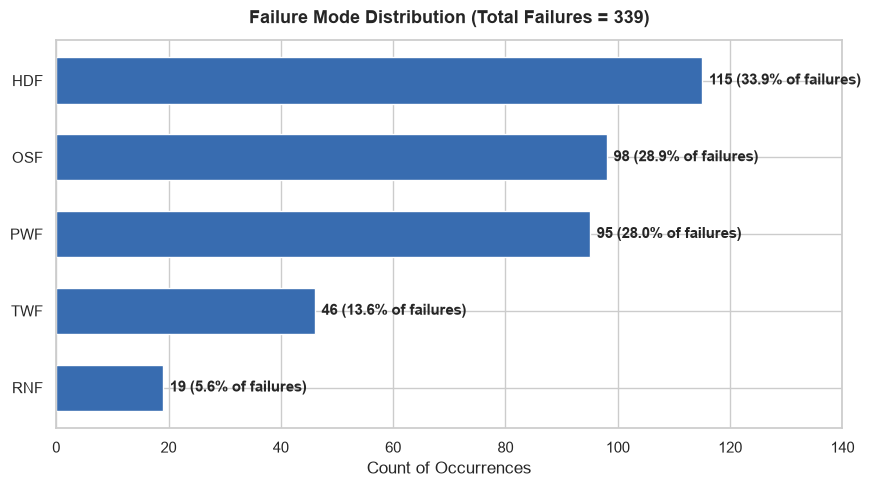

Saved figure to: D:\Projects\Artificial Intelligence\AI-Powered Predictive Maintenance for IoT Devices\images\failure_modes_breakdown.png


In [9]:
failure_sums = df[FAILURE_TYPE_COLUMNS].sum().sort_values(ascending=False)

# Check overlap and unattributed failures
any_mode_flagged = (df[FAILURE_TYPE_COLUMNS].sum(axis=1) > 0).astype(int)
unattributed = df[(df[TARGET_COLUMN] == 1) & (any_mode_flagged == 0)]
rnf_non_failures = df[(df[TARGET_COLUMN] == 0) & (df['RNF'] == 1)]

print("Failure Mode Counts:")
for mode, count in failure_sums.items():
    print(f"  - {mode}: {count} ({count/len(df)*100:.2f}% of all records, {count/339*100:.1f}% of failures)")

print(f"\nAnomalies & Nuances:")
print(f"  - Failures without any specific mode flagged (Unattributed): {len(unattributed)}")
print(f"  - RNF == 1 where Machine failure was NOT asserted (0): {len(rnf_non_failures)}")

# Plotting failure breakdown
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(failure_sums.index[::-1], failure_sums.values[::-1], color="#386cb0", height=0.6)

for bar in bars:
    width = bar.get_width()
    ax.annotate(f"{int(width)} ({width/339*100:.1f}% of failures)",
                xy=(width, bar.get_y() + bar.get_height() / 2),
                xytext=(5, 0), textcoords="offset points",
                ha='left', va='center', fontweight='bold')

ax.set_title("Failure Mode Distribution (Total Failures = 339)", fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel("Count of Occurrences")
ax.set_xlim(0, 140)

fig_modes_path = images_dir / "failure_modes_breakdown.png"
plt.tight_layout()
plt.savefig(fig_modes_path, dpi=300)
plt.show()
print(f"Saved figure to: {fig_modes_path}")


## 8. Physical Boundary Case Study: Power Failure ($P = \tau \cdot \omega$)
Power failure occurs when mechanical power $P = 2\pi \cdot \frac{\text{speed}}{60} \cdot \text{torque} = \frac{\text{speed} \cdot \text{torque}}{9.5488}$ falls outside $[3500\text{ W}, 9000\text{ W}]$.
Below, we plot `Torque [Nm]` versus `Rotational speed [rpm]` colored by `PWF`. This demonstrates how synthetic physics laws govern failure boundaries.


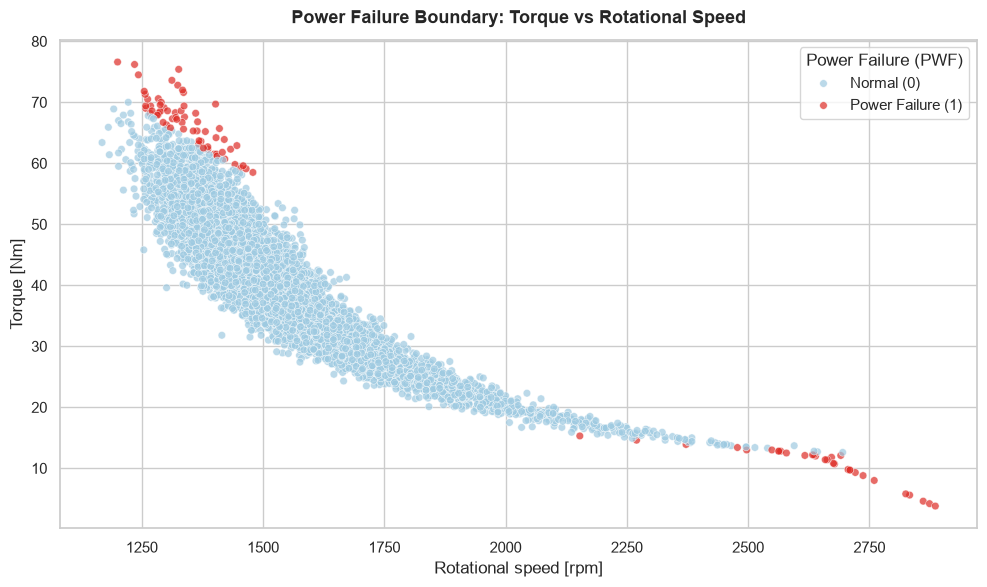

Saved figure to: D:\Projects\Artificial Intelligence\AI-Powered Predictive Maintenance for IoT Devices\images\torque_vs_rotational_speed.png


In [10]:
fig, ax = plt.subplots(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Rotational speed [rpm]",
    y="Torque [Nm]",
    hue="PWF",
    palette={0: "#9ecae1", 1: "#de2d26"},
    alpha=0.7,
    s=30,
    ax=ax
)

ax.set_title("Power Failure Boundary: Torque vs Rotational Speed", fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel("Rotational speed [rpm]")
ax.set_ylabel("Torque [Nm]")
legend = ax.legend(title="Power Failure (PWF)", loc="upper right")
legend.get_texts()[0].set_text("Normal (0)")
legend.get_texts()[1].set_text("Power Failure (1)")

fig_pwf_path = images_dir / "torque_vs_rotational_speed.png"
plt.tight_layout()
plt.savefig(fig_pwf_path, dpi=300)
plt.show()
print(f"Saved figure to: {fig_pwf_path}")


## 9. Summary of Findings & Data Quality Report
### Key Observations
1. **Dataset Integrity**: 10,000 complete records with zero missing values and zero duplicate rows.
2. **Class Imbalance**: High imbalance with only 3.39% failures (28.5:1 ratio). Evaluation must prioritize Precision-Recall AUC, F1-score, and cost-sensitive matrices over raw accuracy.
3. **Physical Signatures**:
   - `Torque` and `Tool wear` have strong positive correlations with failure events.
   - Temperature differential ($T_{\text{process}} - T_{\text{air}}$) strongly controls heat dissipation failure (HDF).
   - Speed vs Torque exhibits distinct hyperbolic power envelopes.
4. **Data Nuances**:
   - 9 failure instances lack an attributed failure mode.
   - 18 instances had random perturbation (`RNF=1`) without triggering the primary failure label.

Below we persist the structured summary to `outputs/eda_summary.json`.


In [11]:
outputs_dir = project_root / "outputs"
outputs_dir.mkdir(parents=True, exist_ok=True)

summary_data = {
    "dataset": "AI4I 2020 Predictive Maintenance",
    "total_rows": int(len(df)),
    "total_columns": int(df.shape[1]),
    "missing_values": int(df.isnull().sum().sum()),
    "duplicate_rows": int(df.duplicated().sum()),
    "target_counts": {str(k): int(v) for k, v in counts.items()},
    "class_imbalance_ratio": round(float(imbalance_ratio), 2),
    "failure_mode_counts": {str(k): int(v) for k, v in failure_sums.items()},
    "unattributed_failures": int(len(unattributed)),
    "rnf_without_failure_flag": int(len(rnf_non_failures))
}

report_path = outputs_dir / "eda_summary.json"
with open(report_path, "w") as f:
    json.dump(summary_data, f, indent=2)

print(f"Summary report persisted to: {report_path}")


Summary report persisted to: D:\Projects\Artificial Intelligence\AI-Powered Predictive Maintenance for IoT Devices\outputs\eda_summary.json
